# Random Forest por actividad productiva (municipios rurales) — objetivo: tasa de deforestación > 0, prueba 2025

> **Versión rural.** Mismo modelo y mismo procedimiento que `random_forest_municipios_con_bosque.ipynb`, pero con la **muestra del gradient
> boosting** del equipo (`modelos y clusters/gradient_boosting.ipynb`): solo municipios **rurales y rurales
> dispersos** (clasificación del DNP) con tasa de deforestación calculable. Son 639 municipios por año, 2.556
> filas de entrenamiento (2021–2024) y 639 de prueba (2025), exactamente las mismas filas del gradient boosting.
> No se exige el mínimo de 100 ha de bosque de la versión anterior. En la comparación de modelos se incluye
> también el gradient boosting, porque ahora los tres se evalúan sobre los mismos municipios.


**Pregunta.** ¿El crédito agropecuario de cada cadena (FINAGRO), el área cosechada de cada cultivo (EVA) y la
ganadería (ICA) de un municipio en un año ayudan a anticipar si ese municipio **tendrá alguna deforestación**
(tasa de deforestación del IDEAM > 0) el año siguiente?

**Diferencias con `modelo_random_forest_por_actividad_aleatorio.ipynb`.** Se usan las mismas 15 variables por
actividad productiva y el mismo procedimiento, con dos cambios:

1. **Variable objetivo:** `deforesta` = 1 si la **tasa de deforestación es mayor que 0**, es decir, si el
   municipio perdió cualquier superficie de bosque. Antes era 1 solo con 10 ha o más.
2. **Partición temporal:** entrenamiento con **2021–2024** y prueba con **2025**. Antes era aleatoria 70/30.

La tabla siguiente compara las variables con las del modelo de totales de 9 variables, que se re-entrena en el
paso 9 como referencia.

| Antes (9 variables) | Ahora (15 variables) |
|---|---|
| `log_credito_prod`, `log_credito_otro`, `prop_cred_ganaderia`, `prop_cred_permanentes` | Crédito de producción por cadena: ganadería, café, arroz, cacao, palma y resto de cadenas |
| `log_area_cosechada` | Área cosechada por cultivo: café, arroz, palma, cacao y resto de cultivos |
| `log_bovinos`, `log_bosque_inicial`, `region`, `ruralidad` | Iguales |

**Pasos** (se omite el análisis exploratorio):

1. Carga de datos
2. Variable objetivo
3. Variables explicativas por actividad (rezagadas un año)
4. Selección de la muestra
5. Partición temporal: entrenamiento 2021–2024 / prueba 2025
6. Preprocesamiento adecuado para árboles
7. Búsqueda de hiperparámetros con `GridSearchCV` (validación cruzada agrupada por municipio)
8. Modelo final y error *out-of-bag*
9. Comparación de modelos en 2025: AUC
10. Comparación de modelos en 2025: matriz de confusión
11. **Importancia de las variables**: impureza, permutación individual, permutación por bloques y dependencia parcial
12. Comparación de especificaciones (estructural, principal, con persistencia)
13. Guardado
14. Conclusiones

## 1. Carga de datos

In [1]:
import os
import time
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
RAIZ = Path.cwd().resolve()
while not (RAIZ / "main_local.py").exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
os.chdir(RAIZ)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", 40, "display.width", 200)
SEMILLA = 42

panel = pd.read_parquet("datos/analisis/municipio_anio.parquet")
print(panel.shape)

(6738, 28)


## 2. Variable objetivo

`deforesta` = 1 si la **tasa de deforestación del IDEAM** del municipio en el año *t* es **mayor que 0**; 0 si es
cero. La tasa es `def_ideam_ha / bosque_ideam_ha`. Como en la muestra todos los municipios tienen bosque, la
condición "tasa > 0" equivale a "perdió alguna superficie de bosque, aunque sea una fracción de hectárea". A diferencia del umbral anterior de 10 ha,
cualquier pérdida cuenta, incluso las muy pequeñas.

In [2]:
REGLA_OBJETIVO = "tasa_def_ideam > 0"

panel = panel.sort_values(["cod_dane", "anio"]).reset_index(drop=True)
panel["deforesta"] = np.where(panel.tasa_def_ideam.isna(), np.nan, (panel.tasa_def_ideam > 0).astype(float))

d = panel[panel.anio.between(2021, 2025)]
print("Pérdida de bosque (ha) en los municipio-año con tasa > 0:")
print(d.loc[d.deforesta == 1, "def_ideam_ha"].describe(percentiles=[0.1, 0.25, 0.5, 0.75]).round(2).to_string())

Pérdida de bosque (ha) en los municipio-año con tasa > 0:
count     2766.00
mean       220.01
std        985.41
min          0.06
10%          1.31
25%          3.62
50%         18.38
75%         94.25
max      17041.50


## 3. Variables explicativas por actividad productiva

Todas las variables de crédito, cultivos y ganado se toman del **año anterior** (*t − 1*), para reducir la
causalidad inversa. Montos y áreas se transforman con log(1 + x) porque son muy asimétricos y tienen muchos
ceros. Para un árbol, el logaritmo no cambia las particiones; se aplica para que las curvas de dependencia
parcial se lean en una escala razonable.

| # | Variable | Definición (en *t − 1*) | Fuente |
|---|---|---|---|
| 1 | `log_credito_ganaderia` | Crédito del eslabón de producción a ganadería (doble propósito, leche, carne), millones de pesos | FINAGRO |
| 2 | `log_credito_cafe` | Ídem, café | FINAGRO |
| 3 | `log_credito_arroz` | Ídem, arroz | FINAGRO |
| 4 | `log_credito_cacao` | Ídem, cacao | FINAGRO |
| 5 | `log_credito_palma` | Ídem, palma de aceite | FINAGRO |
| 6 | `log_credito_otras_cadenas` | Crédito de producción de las demás cadenas: total de producción menos las cinco anteriores | FINAGRO |
| 7 | `log_cosechada_cafe` | Hectáreas cosechadas de café | EVA |
| 8 | `log_cosechada_arroz` | Ídem, arroz | EVA |
| 9 | `log_cosechada_palma` | Ídem, palma de aceite | EVA |
| 10 | `log_cosechada_cacao` | Ídem, cacao | EVA |
| 11 | `log_cosechada_otros` | Hectáreas cosechadas de los demás cultivos: total menos los cuatro anteriores | EVA |
| 12 | `log_bovinos` | Inventario bovino (cabezas) | ICA |
| 13 | `log_bosque_inicial` | Hectáreas de bosque del municipio al inicio del panel (fija) | IDEAM |
| 14 | `region` | Región del municipio (categórica) | Municipios |
| 15 | `ruralidad` | Categoría de ruralidad (categórica) | Municipios |

`log_credito_otras_cadenas` es crédito del eslabón de **producción**. No incluye el crédito de transformación,
comercialización y servicios (el antiguo `log_credito_otro`), que ya no se usa.

También se construyen las variables del modelo anterior de 9 variables, solo para compararlo en el paso 9.

In [3]:
p = panel.copy()
CADENAS = {"ganaderia": "credito_ganaderia_produccion_mm", "cafe": "credito_cafe_produccion_mm",
           "arroz": "credito_arroz_produccion_mm", "cacao": "credito_cacao_produccion_mm",
           "palma": "credito_palma_produccion_mm"}
CULTIVOS = {"cafe": "cosechada_cafe_ha", "arroz": "cosechada_arroz_ha", "palma": "cosechada_palma_ha",
            "cacao": "cosechada_cacao_ha"}

p["credito_otras_cadenas_mm"] = (p.credito_produccion_mm - p[list(CADENAS.values())].sum(axis=1)).clip(lower=0)
p["cosechada_otros_ha"] = (p.area_cosechada_ha - p[list(CULTIVOS.values())].sum(axis=1, min_count=1)).clip(lower=0)

# Variables del modelo anterior (solo para comparar)
p["credito_otro_mm"] = (p.credito_mm - p.credito_produccion_mm).clip(lower=0)
cred_prod = p.credito_produccion_mm.replace(0, np.nan)
p["prop_cred_ganaderia_t"] = (p.credito_ganaderia_produccion_mm / cred_prod).fillna(0)
p["prop_cred_permanentes_t"] = (p[["credito_palma_produccion_mm", "credito_cacao_produccion_mm",
                                   "credito_cafe_produccion_mm"]].sum(axis=1) / cred_prod).fillna(0)

# Rezago de un anio dentro de cada municipio
g = p.groupby("cod_dane", observed=True)
assert (g.anio.diff().dropna() == 1).all(), "hay anios faltantes dentro de algun municipio"
a_rezagar = {**{f"log_credito_{k}": v for k, v in CADENAS.items()},
             "log_credito_otras_cadenas": "credito_otras_cadenas_mm",
             **{f"log_cosechada_{k}": v for k, v in CULTIVOS.items()},
             "log_cosechada_otros": "cosechada_otros_ha",
             "log_bovinos": "bovinos", "log_def_l1": "def_ideam_ha",
             # modelo anterior
             "log_credito_prod": "credito_produccion_mm", "log_credito_otro": "credito_otro_mm",
             "log_area_cosechada": "area_cosechada_ha"}
for nuevo, col in a_rezagar.items():
    p[nuevo] = np.log1p(g[col].shift(1))
p["prop_cred_ganaderia"] = g.prop_cred_ganaderia_t.shift(1)
p["prop_cred_permanentes"] = g.prop_cred_permanentes_t.shift(1)
p["log_bosque_inicial"] = np.log1p(p.bosque_ideam_inicial_ha)

CREDITO = [f"log_credito_{k}" for k in CADENAS] + ["log_credito_otras_cadenas"]
COSECHA = [f"log_cosechada_{k}" for k in CULTIVOS] + ["log_cosechada_otros"]
NUMERICAS = CREDITO + COSECHA + ["log_bovinos", "log_bosque_inicial"]
CATEGORICAS = ["region", "ruralidad"]
X_COLS = NUMERICAS + CATEGORICAS
NUMERICAS_ANT = ["log_credito_prod", "log_credito_otro", "prop_cred_ganaderia", "prop_cred_permanentes",
                 "log_area_cosechada", "log_bovinos", "log_bosque_inicial"]
print(f"{len(X_COLS)} variables: {len(CREDITO)} de credito, {len(COSECHA)} de cosecha, bovinos, bosque y 2 categoricas")

15 variables: 6 de credito, 5 de cosecha, bovinos, bosque y 2 categoricas


## 4. Selección de la muestra

Misma muestra del gradient boosting: años objetivo 2021–2025, municipios **rurales o rurales dispersos** y con
tasa de deforestación calculable (es decir, con bosque). Se verifica que las filas coincidan exactamente con
las del gradient boosting.

In [4]:
RURALES = ["Rural", "Rural disperso"]
BOSQUE_MIN_HA = 0  # sin minimo de bosque: misma muestra del gradient boosting

muestra = p[p.anio.between(2021, 2025) & p.ruralidad.isin(RURALES) & p.tasa_def_ideam.notna()].copy()
muestra["deforesta"] = muestra.deforesta.astype(int)
print(f"Filas: {len(muestra):,} | municipios: {muestra.cod_dane.nunique():,} | "
      f"0: {(muestra.deforesta == 0).sum():,} | 1: {(muestra.deforesta == 1).sum():,}")

# Verificacion: mismas filas (municipio, anio) que el gradient boosting
import json
celdas_gb = ["".join(c["source"]) for c in json.load(open("modelos y clusters/gradient_boosting.ipynb", encoding="utf-8"))["cells"]]
ns_gb = {"np": np, "pd": pd, "DIR_ANALISIS": Path("datos/analisis")}
exec(celdas_gb[4], ns_gb)  # carga del panel y filtro rural del gradient boosting
exec(celdas_gb[6], ns_gb)  # sus 15 variables y su muestra
filas_gb = set(zip(ns_gb["muestra"].cod_dane.astype(str), ns_gb["muestra"].anio))
filas_propias = set(zip(muestra.cod_dane.astype(str), muestra.anio))
assert filas_gb == filas_propias, "la muestra no coincide con la del gradient boosting"
print("La muestra coincide exactamente con la del gradient boosting.")

Filas: 3,195 | municipios: 639 | 0: 1,176 | 1: 2,019
Filas: 3,852  ·  Municipios rurales: 642  ·  Años: [np.int64(2020), np.int64(2021), np.int64(2022), np.int64(2023), np.int64(2024), np.int64(2025)]
Filas utilizables (2021-2025, con bosque): 3,195
Municipios-año con deforestación > 0: 2,019 (63.2 %)
La muestra coincide exactamente con la del gradient boosting.


## 5. Partición temporal

**Entrenamiento: 2021, 2022, 2023 y 2024. Prueba: 2025.** El modelo aprende con cuatro años y se evalúa en un año
que no conoce. Es lo más parecido a su uso real: predecir el año siguiente con lo que se sabe hasta hoy.

In [5]:
ANIOS_TRAIN, ANIOS_TEST = [2021, 2022, 2023, 2024], [2025]
train = muestra[muestra.anio.isin(ANIOS_TRAIN)]
test = muestra[muestra.anio.isin(ANIOS_TEST)]
X_train, y_train, grupos_train = train[X_COLS], train.deforesta, train.cod_dane.astype(str)
X_test, y_test = test[X_COLS], test.deforesta

pd.DataFrame({"filas": [len(train), len(test)], "ceros": [(y_train == 0).sum(), (y_test == 0).sum()],
              "unos": [(y_train == 1).sum(), (y_test == 1).sum()], "tasa_deforesta": [y_train.mean(), y_test.mean()]},
             index=["entrenamiento 2021-2024", "prueba 2025"]).round(3)

,filas,ceros,unos,tasa_deforesta
entrenamiento 2021-2024,2556,947,1609,0.629
prueba 2025,639,229,410,0.642


## 6. Preprocesamiento adecuado para árboles

| Transformación | ¿Se necesita? | Por qué |
|---|---|---|
| **Imputación** | **Sí** | `RandomForestClassifier` no acepta `NaN`. Se usa la mediana o la moda, aprendidas solo en entrenamiento. |
| **One-hot** de categóricas | **Sí** | Los árboles necesitan números. Se usa *one-hot* completo, sin eliminar categorías. |
| **Estandarización** | **No** | Una división "x ≤ c" no cambia al reescalar x. Se comprueba abajo: las probabilidades coinciden salvo diferencias mínimas por empates numéricos. Cuando dos divisiones son igual de buenas, el redondeo de la escala puede decidir cuál se elige en algún árbol. |
| **Logaritmos** | Inofensivos | Son monótonos y no cambian las particiones. |

Además se revisan las **correlaciones fuertes** entre variables. No afectan la capacidad predictiva del bosque,
pero cuando dos variables están muy correlacionadas (por ejemplo, crédito al café y área de café) se reparten
la importancia. Por eso en el paso 11 se mide también la importancia por **bloques**.

In [6]:
from sklearn.compose import ColumnTransformer
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler


def preprocesador(num=NUMERICAS, escalar=False):
    pasos_num = [("imp", SimpleImputer(strategy="median"))] + ([("esc", StandardScaler())] if escalar else [])
    return ColumnTransformer([
        ("num", Pipeline(pasos_num), num),
        ("cat", Pipeline([("imp", SimpleImputer(strategy="most_frequent")),
                          ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))]), CATEGORICAS),
    ], verbose_feature_names_out=False)


rf_prueba = dict(n_estimators=200, random_state=SEMILLA, n_jobs=-1)
sin_esc = Pipeline([("pre", preprocesador()), ("rf", RandomForestClassifier(**rf_prueba))]).fit(X_train, y_train)
con_esc = Pipeline([("pre", preprocesador(escalar=True)), ("rf", RandomForestClassifier(**rf_prueba))]).fit(X_train, y_train)
dif = np.abs(sin_esc.predict_proba(X_test)[:, 1] - con_esc.predict_proba(X_test)[:, 1])
print(f"Diferencia de probabilidad con vs. sin estandarizar: maxima {dif.max():.3f} (1 arbol de 200 = 0.005) | "
      f"promedio {dif.mean():.5f} | filas identicas {np.mean(dif == 0):.1%}")
print(f"Columnas que recibe el bosque: {len(preprocesador().fit(X_train).get_feature_names_out())}")

corr = X_train[NUMERICAS].corr(method="spearman")
pares = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1)).stack().rename("rho_spearman")
         .loc[lambda s: s.abs() >= 0.6].sort_values(key=abs, ascending=False))
print("\nPares con |correlacion de Spearman| >= 0,6:")
pares.round(3).to_frame()

Diferencia de probabilidad con vs. sin estandarizar: maxima 0.000 (1 arbol de 200 = 0.005) | promedio 0.00000 | filas identicas 100.0%
Columnas que recibe el bosque: 21

Pares con |correlacion de Spearman| >= 0,6:


,,rho_spearman
log_credito_cafe,log_cosechada_cafe,0.924
log_credito_ganaderia,log_bovinos,0.820
log_credito_palma,log_cosechada_palma,0.795
log_credito_cacao,log_cosechada_cacao,0.789
log_credito_arroz,log_cosechada_arroz,0.601


## 7. Búsqueda de hiperparámetros con `GridSearchCV`

| Hiperparámetro | Qué controla | Valores probados |
|---|---|---|
| `n_estimators` | número de árboles | 300, 600 |
| `max_depth` | profundidad máxima de cada árbol | 4, 8, 12, sin límite |
| `min_samples_leaf` | mínimo de observaciones por hoja | 1, 5, 10, 25 |
| `max_features` | proporción de variables sorteadas en cada división | `sqrt`, 0,5, todas |
| `class_weight` | peso de la clase minoritaria en cada muestra *bootstrap* | ninguno, `balanced_subsample` |

Son 192 combinaciones, evaluadas con `GroupKFold` de 5 pliegues **agrupados por municipio**: un municipio nunca
está a la vez en ajuste y validación. La métrica es el AUC-ROC, y también se registra el AUC de entrenamiento
para ver el sobreajuste.

In [7]:
from sklearn.model_selection import GridSearchCV, GroupKFold

modelo = Pipeline([("pre", preprocesador()), ("rf", RandomForestClassifier(random_state=SEMILLA, n_jobs=1))])
grilla = {
    "rf__n_estimators": [300, 600],
    "rf__max_depth": [4, 8, 12, None],
    "rf__min_samples_leaf": [1, 5, 10, 25],
    "rf__max_features": ["sqrt", 0.5, 1.0],
    "rf__class_weight": [None, "balanced_subsample"],
}
cv = GroupKFold(n_splits=5)
busqueda = GridSearchCV(modelo, grilla, cv=cv, scoring=["roc_auc", "average_precision", "neg_log_loss"],
                        refit="roc_auc", n_jobs=-1, return_train_score=True)
inicio = time.time()
busqueda.fit(X_train, y_train, groups=grupos_train)
print(f"{len(busqueda.cv_results_['params'])} combinaciones x 5 pliegues en {(time.time() - inicio) / 60:.1f} min")
print("Mejor combinacion:", {k.replace('rf__', ''): v for k, v in busqueda.best_params_.items()})
print("AUC validacion:", round(busqueda.best_score_, 4))

res = pd.DataFrame(busqueda.cv_results_)
cols = {f"param_rf__{k}": k for k in ["n_estimators", "max_depth", "min_samples_leaf", "max_features", "class_weight"]}
cols.update({"mean_test_roc_auc": "AUC_val", "std_test_roc_auc": "AUC_val_sd", "mean_train_roc_auc": "AUC_train",
             "mean_test_average_precision": "AP_val", "mean_test_neg_log_loss": "neg_logloss_val"})
tabla_cv = res[list(cols)].rename(columns=cols)
tabla_cv["brecha_train_val"] = tabla_cv.AUC_train - tabla_cv.AUC_val
tabla_cv.sort_values("AUC_val", ascending=False).head(10).round(4)

192 combinaciones x 5 pliegues en 42.5 min
Mejor combinacion: {'class_weight': None, 'max_depth': 12, 'max_features': 1.0, 'min_samples_leaf': 25, 'n_estimators': 600}
AUC validacion: 0.9127


,n_estimators,max_depth,min_samples_leaf,max_features,class_weight,AUC_val,AUC_val_sd,AUC_train,AP_val,neg_logloss_val,brecha_train_val
95,600,None,25,1.0,None,0.9127,0.0163,0.9470,0.9502,-0.3564,0.0343
71,600,12,25,1.0,None,0.9127,0.0163,0.9470,0.9502,-0.3564,0.0343
47,600,8,25,1.0,None,0.9127,0.0163,0.9470,0.9502,-0.3564,0.0343
94,300,None,25,1.0,None,0.9124,0.0164,0.9471,0.9499,-0.3567,0.0347
70,300,12,25,1.0,None,0.9124,0.0164,0.9471,0.9499,-0.3567,0.0347
86,300,None,25,0.5,None,0.9124,0.0179,0.9447,0.9501,-0.3584,0.0323
46,300,8,25,1.0,None,0.9124,0.0164,0.9471,0.9499,-0.3567,0.0347
62,300,12,25,0.5,None,0.9124,0.0179,0.9447,0.9501,-0.3584,0.0323
191,600,None,25,1.0,balanced_subsample,0.9122,0.0162,0.9468,0.9499,-0.3682,0.0346
167,600,12,25,1.0,balanced_subsample,0.9122,0.0162,0.9468,0.9499,-0.3682,0.0346


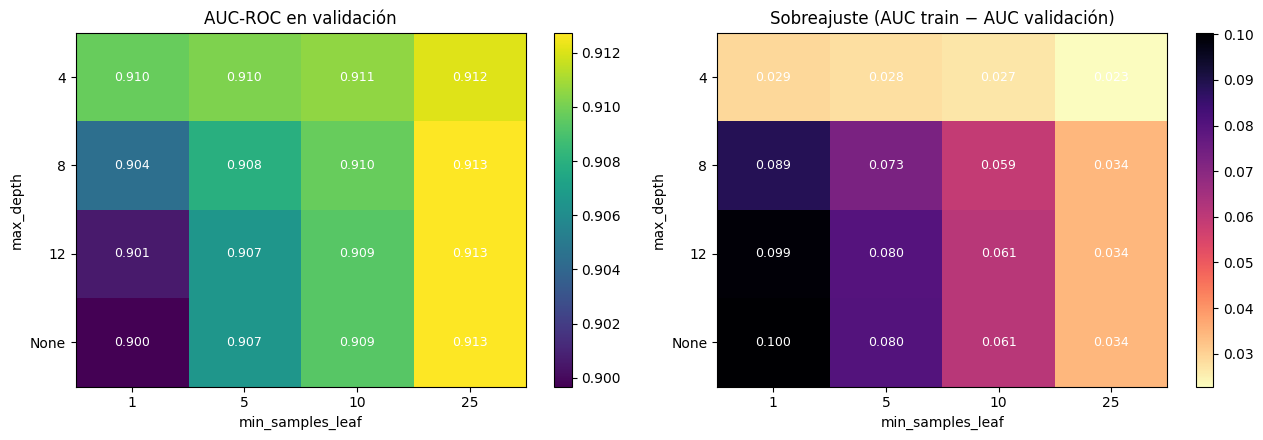

In [8]:
mejor = busqueda.best_params_
fijo = tabla_cv[(tabla_cv.n_estimators == mejor["rf__n_estimators"]) & (tabla_cv.max_features.astype(str) == str(mejor["rf__max_features"]))
                & (tabla_cv.class_weight.astype(str) == str(mejor["rf__class_weight"]))].copy()
fijo["max_depth"] = fijo.max_depth.astype(str)

fig, ax = plt.subplots(1, 2, figsize=(13, 4.5))
for metrica, eje, titulo in [("AUC_val", ax[0], "AUC-ROC en validación"), ("brecha_train_val", ax[1], "Sobreajuste (AUC train − AUC validación)")]:
    tabla = fijo.pivot_table(index="max_depth", columns="min_samples_leaf", values=metrica).reindex(["4", "8", "12", "None"])
    im = eje.imshow(tabla.values, cmap="viridis" if metrica == "AUC_val" else "magma_r", aspect="auto")
    eje.set_xticks(range(tabla.shape[1]), tabla.columns); eje.set_yticks(range(tabla.shape[0]), tabla.index)
    eje.set_xlabel("min_samples_leaf"); eje.set_ylabel("max_depth"); eje.set_title(titulo)
    for i in range(tabla.shape[0]):
        for j in range(tabla.shape[1]):
            eje.text(j, i, f"{tabla.values[i, j]:.3f}", ha="center", va="center", color="white", fontsize=9)
    plt.colorbar(im, ax=eje)
plt.tight_layout(); plt.show()

## 8. Modelo final y error *out-of-bag*

`GridSearchCV` re-entrena la mejor combinación con todo el entrenamiento (2021–2024). Como chequeo, el mismo
bosque se ajusta con `oob_score=True`. El OOB es algo optimista aquí, porque las filas que quedan fuera de un
árbol pueden ser otros años del mismo municipio.

In [9]:
from sklearn.base import clone
from sklearn.metrics import roc_auc_score

final = busqueda.best_estimator_
oob = clone(final).set_params(rf__oob_score=True, rf__n_jobs=-1).fit(X_train, y_train)
print(f"AUC out-of-bag: {roc_auc_score(y_train, oob.named_steps['rf'].oob_decision_function_[:, 1]):.4f} "
      f"| AUC validacion cruzada agrupada: {busqueda.best_score_:.4f}")
final.named_steps["rf"]

AUC out-of-bag: 0.9215 | AUC validacion cruzada agrupada: 0.9127


,n_estimators,600
,criterion,'gini'
,max_depth,12
,min_samples_split,2
,min_samples_leaf,25
,min_weight_fraction_leaf,0.0
,max_features,1.0
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


## 9. Comparación de modelos: AUC

Los modelos se comparan sobre los mismos 639 municipios de 2025 con el **AUC-ROC**: la probabilidad de que un
municipio que deforestó reciba una probabilidad mayor que uno que no deforestó (0,5 = azar, 1 = perfecto).

- **RF por actividad (15 variables):** el modelo de este notebook.
- **RF de totales (9 variables):** las variables de `modelo_random_forest.ipynb` y sus hiperparámetros (600 árboles,
  `max_depth = 12`, `min_samples_leaf = 10`), re-entrenado con la misma variable objetivo y el mismo entrenamiento.
- **Gradient boosting (equipo):** el modelo guardado de `modelos y clusters/gradient_boosting.ipynb`, con sus
  propias 15 variables (del mismo año que predice). Se evalúa sobre los mismos 639 municipios.
- **Persistencia:** asigna la probabilidad observada en el entrenamiento según si el municipio deforestó o no el
  año anterior. Muestra cuánto agrega el modelo más allá de "lo que pasó el año pasado".

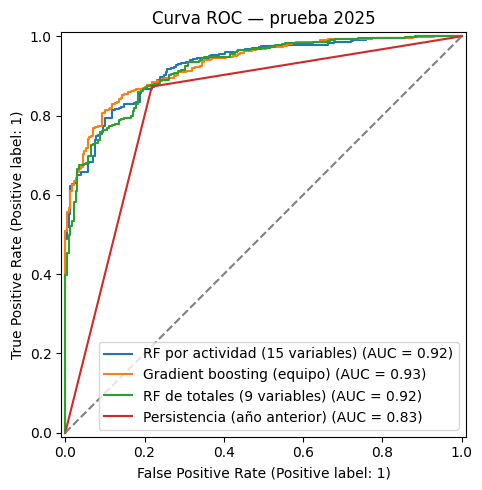

,AUC-ROC
RF por actividad (15 variables),0.9246
Gradient boosting (equipo),0.9278
RF de totales (9 variables),0.9205
Persistencia (año anterior),0.8274


In [10]:
from sklearn.metrics import RocCurveDisplay, roc_auc_score


def metricas(y, prob):
    return {"AUC-ROC": roc_auc_score(y, prob)}


PARAMS_ANT = dict(n_estimators=600, max_depth=12, min_samples_leaf=10, max_features="sqrt", class_weight=None)
anterior = Pipeline([("pre", preprocesador(NUMERICAS_ANT)),
                     ("rf", RandomForestClassifier(random_state=SEMILLA, n_jobs=-1, **PARAMS_ANT))])
anterior.fit(train[NUMERICAS_ANT + CATEGORICAS], y_train)

p["deforesta_l1"] = p.groupby("cod_dane", observed=True).deforesta.shift(1)
tasa_cond = train.assign(l1=p.loc[train.index, "deforesta_l1"]).groupby("l1").deforesta.mean()

prob_test = final.predict_proba(X_test)[:, 1]
prob_ant = anterior.predict_proba(test[NUMERICAS_ANT + CATEGORICAS])[:, 1]
prob_pers = p.loc[test.index, "deforesta_l1"].map(tasa_cond).fillna(y_train.mean()).values


# --- Gradient boosting del equipo, sobre los mismos municipios de 2025
import joblib
import lightgbm  # noqa: F401  (necesario para cargar el modelo)
test_gb = ns_gb["muestra"].query("anio == 2025").assign(cod_dane=lambda d: d.cod_dane.astype(str)).set_index("cod_dane")
gb = joblib.load("modelos y clusters/resultados/gradient_boosting_clasificador.joblib")
prob_gb = gb.predict_proba(test_gb.loc[test.cod_dane.astype(str), ns_gb["EXPLICATIVAS"]])[:, 1]
modelos = {"RF por actividad (15 variables)": prob_test, "Gradient boosting (equipo)": prob_gb,
           "RF de totales (9 variables)": prob_ant,
           "Persistencia (año anterior)": prob_pers}
tabla_eval = pd.DataFrame({k: metricas(y_test, v) for k, v in modelos.items()}).T

fig, ax = plt.subplots(figsize=(6, 5))
for nombre, prob in modelos.items():
    RocCurveDisplay.from_predictions(y_test, prob, ax=ax, name=nombre)
ax.plot([0, 1], [0, 1], "--", color="grey"); ax.set_title("Curva ROC — prueba 2025")
plt.tight_layout(); plt.show()
tabla_eval.round(4)

## 10. Comparación de modelos: matriz de confusión

Cada modelo clasifica los municipios de 2025 con el **mismo umbral de 0,5**: si la probabilidad predicha es
0,5 o más, se clasifica como "deforesta". Usar el mismo umbral permite comparar los modelos directamente, y
0,5 es también el umbral que usa el gradient boosting (`predict`).

- **Verdaderos positivos:** municipios que deforestaron y el modelo los detectó.
- **Falsos negativos:** municipios que deforestaron y el modelo no los detectó.
- **Falsos positivos:** municipios que no deforestaron pero el modelo los marcó.
- **Verdaderos negativos:** municipios que no deforestaron y el modelo acertó.

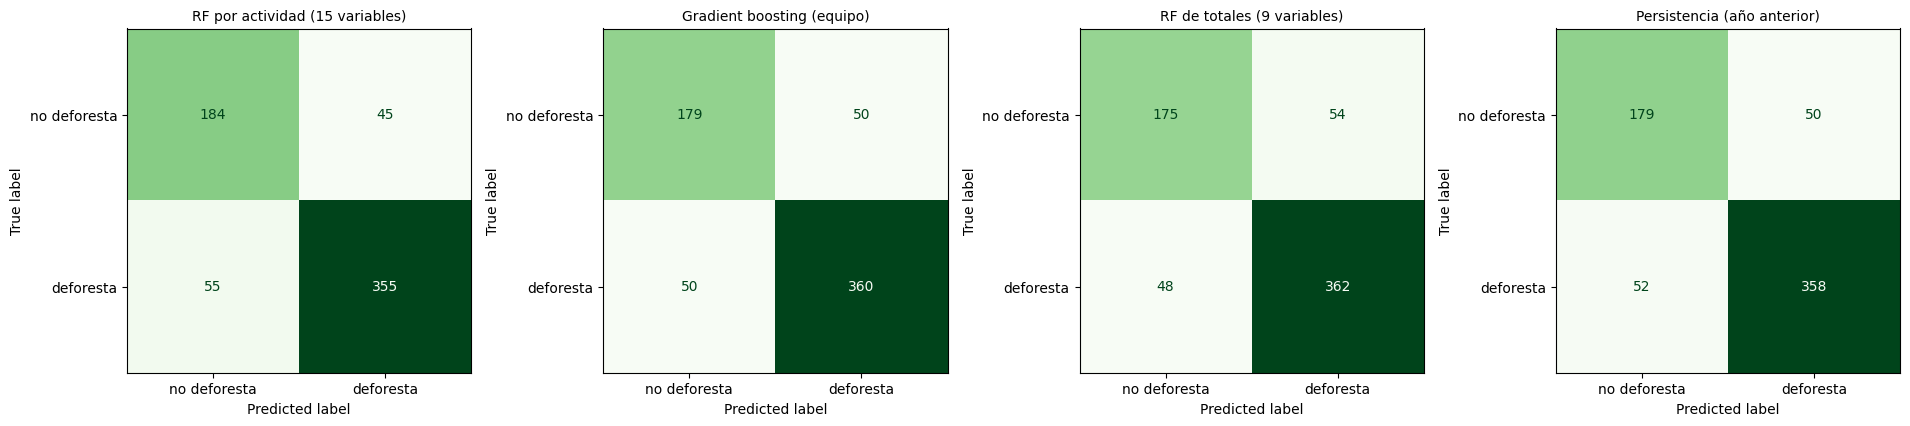

,verdaderos negativos,falsos positivos,falsos negativos,verdaderos positivos,aciertos
modelo,,,,,
RF por actividad (15 variables),184,45,55,355,539
Gradient boosting (equipo),179,50,50,360,539
RF de totales (9 variables),175,54,48,362,537
Persistencia (año anterior),179,50,52,358,537


In [11]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

UMBRAL = 0.5
fig, ax = plt.subplots(1, len(modelos), figsize=(4.8 * len(modelos), 4.3))
filas = []
for eje, (nombre, prob) in zip(np.atleast_1d(ax), modelos.items()):
    pred = (prob >= UMBRAL).astype(int)
    cm = confusion_matrix(y_test, pred)
    ConfusionMatrixDisplay(cm, display_labels=["no deforesta", "deforesta"]).plot(ax=eje, cmap="Greens", colorbar=False)
    eje.set_title(nombre, fontsize=10)
    tn, fp, fn, tp = cm.ravel()
    filas.append({"modelo": nombre, "verdaderos negativos": tn, "falsos positivos": fp,
                  "falsos negativos": fn, "verdaderos positivos": tp, "aciertos": tn + tp})
plt.tight_layout(); plt.show()
pred_test = (prob_test >= UMBRAL).astype(int)
matrices = pd.DataFrame(filas).set_index("modelo")
matrices

## 11. Importancia de las variables

Se calculan cuatro medidas:

1. **Impureza (MDI)**: reducción de Gini en el entrenamiento. Las columnas *one-hot* se suman por variable
   original. Favorece a las variables continuas con muchos valores.
2. **Permutación individual** (en la **prueba 2025**): caída del AUC al desordenar una variable, con 30 repeticiones.
3. **Permutación por bloques temáticos**: se desordenan **juntas** todas las variables de un bloque (todo el
   crédito, toda la cosecha...). Así no se subestiman variables correlacionadas entre sí.
4. **Permutación por actividad productiva**: se desordenan juntos el crédito y el área de cada actividad
   (crédito y área de café; crédito ganadero y bovinos...). Responde cuánto aporta cada actividad en conjunto.

In [12]:
from sklearn.inspection import permutation_importance

rf = final.named_steps["rf"]
nombres = pd.Index(final.named_steps["pre"].get_feature_names_out())
original = lambda c: next((v for v in CATEGORICAS if c.startswith(v + "_")), c)
mdi = pd.Series(rf.feature_importances_, index=nombres).groupby(nombres.map(original)).sum()
mdi_sd = pd.Series(np.std([a.feature_importances_ for a in rf.estimators_], axis=0), index=nombres).groupby(nombres.map(original)).sum()

perm = permutation_importance(final, X_test, y_test, scoring="roc_auc", n_repeats=30, random_state=SEMILLA, n_jobs=-1)
importancia = pd.DataFrame({"MDI": mdi, "MDI_sd": mdi_sd,
                            "permutacion_caida_AUC": pd.Series(perm.importances_mean, index=X_COLS),
                            "permutacion_sd": pd.Series(perm.importances_std, index=X_COLS)})
importancia["rango_MDI"] = importancia.MDI.rank(ascending=False).astype(int)
importancia["rango_permutacion"] = importancia.permutacion_caida_AUC.rank(ascending=False).astype(int)
importancia = importancia.sort_values("permutacion_caida_AUC", ascending=False)
importancia.round(4)

,MDI,MDI_sd,permutacion_caida_AUC,permutacion_sd,rango_MDI,rango_permutacion
log_bosque_inicial,0.7735,0.0211,0.3634,0.0166,1,1
log_cosechada_cacao,0.0571,0.0223,0.0211,0.0034,2,2
log_bovinos,0.0478,0.0253,0.0154,0.0029,3,3
region,0.0161,0.0318,0.0070,0.0012,6,4
log_credito_ganaderia,0.0208,0.0131,0.0045,0.0009,5,5
log_cosechada_cafe,0.0278,0.0137,0.0036,0.0018,4,6
log_credito_otras_cadenas,0.0132,0.0098,0.0021,0.0006,9,7
log_credito_cafe,0.0146,0.0112,0.0018,0.0006,7,8
log_cosechada_otros,0.0139,0.0101,0.0018,0.0006,8,9
log_credito_cacao,0.0099,0.0119,0.0011,0.0005,10,10


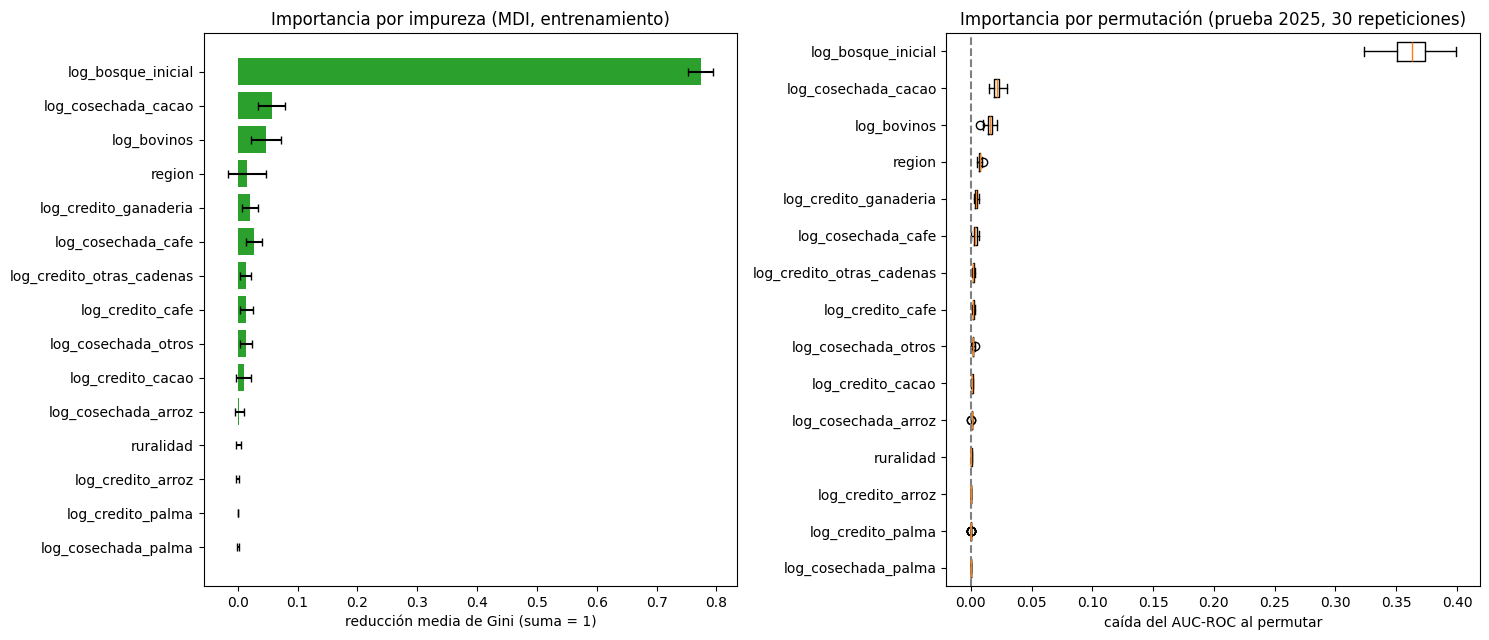

In [13]:
orden = importancia.index[::-1]
fig, ax = plt.subplots(1, 2, figsize=(15, 6.5))
ax[0].barh(orden, importancia.loc[orden, "MDI"], xerr=importancia.loc[orden, "MDI_sd"], color="C2", capsize=3)
ax[0].set_title("Importancia por impureza (MDI, entrenamiento)"); ax[0].set_xlabel("reducción media de Gini (suma = 1)")
ax[1].boxplot(pd.DataFrame(perm.importances.T, columns=X_COLS)[orden].values, vert=False, labels=orden)
ax[1].axvline(0, ls="--", color="grey")
ax[1].set_title("Importancia por permutación (prueba 2025, 30 repeticiones)"); ax[1].set_xlabel("caída del AUC-ROC al permutar")
plt.tight_layout(); plt.show()

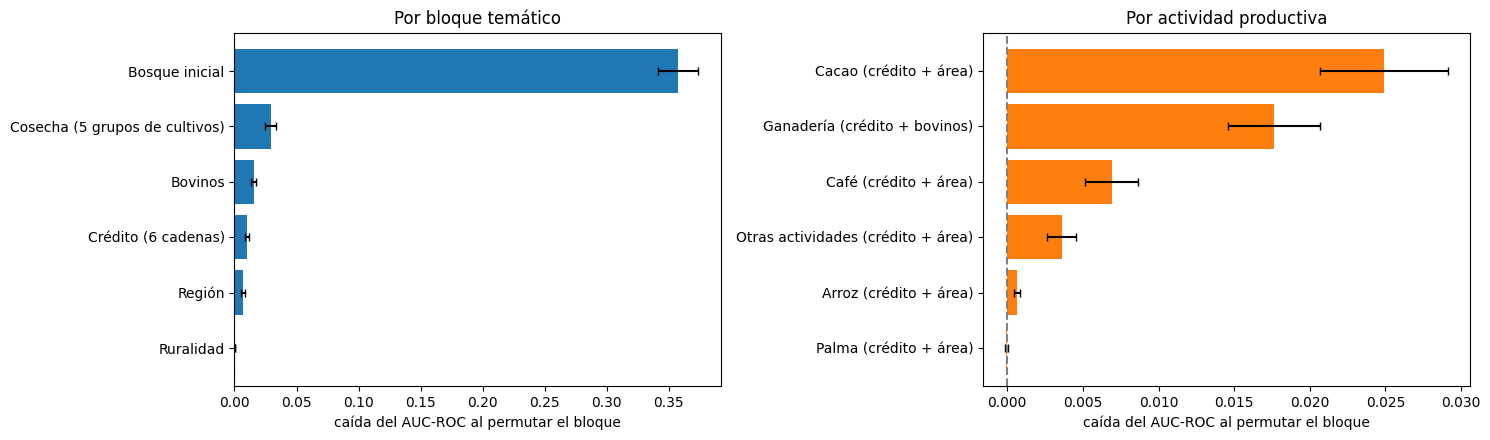

,n_variables,caida_AUC,sd
bloque,,,
Bosque inicial,1,0.3574,0.0162
Cosecha (5 grupos de cultivos),5,0.0291,0.0048
Bovinos,1,0.0156,0.0020
Crédito (6 cadenas),6,0.0100,0.0016
Región,1,0.0069,0.0012
Ruralidad,1,0.0005,0.0002


,n_variables,caida_AUC,sd
bloque,,,
Cacao (crédito + área),2,0.0249,0.0042
Ganadería (crédito + bovinos),2,0.0176,0.0030
Café (crédito + área),2,0.0069,0.0017
Otras actividades (crédito + área),2,0.0036,0.0010
Arroz (crédito + área),2,0.0006,0.0002
Palma (crédito + área),2,-0.0001,0.0001


In [14]:
def permutar_bloques(modelo, X, y, bloques, n_repeats=30, semilla=SEMILLA):
    """Caida del AUC al desordenar juntas (con la misma permutacion de filas) las columnas de cada bloque."""
    rng = np.random.default_rng(semilla)
    base = roc_auc_score(y, modelo.predict_proba(X)[:, 1])
    filas = []
    for nombre, cols in bloques.items():
        caidas = []
        for _ in range(n_repeats):
            Xp = X.copy()
            Xp[cols] = X[cols].values[rng.permutation(len(X))]
            caidas.append(base - roc_auc_score(y, modelo.predict_proba(Xp)[:, 1]))
        filas.append({"bloque": nombre, "n_variables": len(cols), "caida_AUC": np.mean(caidas), "sd": np.std(caidas)})
    return pd.DataFrame(filas).set_index("bloque").sort_values("caida_AUC", ascending=False)


BLOQUES = {"Crédito (6 cadenas)": CREDITO, "Cosecha (5 grupos de cultivos)": COSECHA, "Bovinos": ["log_bovinos"],
           "Bosque inicial": ["log_bosque_inicial"], "Región": ["region"], "Ruralidad": ["ruralidad"]}
ACTIVIDADES = {"Ganadería (crédito + bovinos)": ["log_credito_ganaderia", "log_bovinos"],
               "Café (crédito + área)": ["log_credito_cafe", "log_cosechada_cafe"],
               "Arroz (crédito + área)": ["log_credito_arroz", "log_cosechada_arroz"],
               "Cacao (crédito + área)": ["log_credito_cacao", "log_cosechada_cacao"],
               "Palma (crédito + área)": ["log_credito_palma", "log_cosechada_palma"],
               "Otras actividades (crédito + área)": ["log_credito_otras_cadenas", "log_cosechada_otros"]}
imp_bloques = permutar_bloques(final, X_test, y_test, BLOQUES)
imp_actividades = permutar_bloques(final, X_test, y_test, ACTIVIDADES)

fig, ax = plt.subplots(1, 2, figsize=(15, 4.5))
for eje, tabla, titulo, color in [(ax[0], imp_bloques, "Por bloque temático", "C0"), (ax[1], imp_actividades, "Por actividad productiva", "C1")]:
    t = tabla.iloc[::-1]
    eje.barh(t.index, t.caida_AUC, xerr=t.sd, color=color, capsize=3)
    eje.axvline(0, ls="--", color="grey"); eje.set_xlabel("caída del AUC-ROC al permutar el bloque"); eje.set_title(titulo)
plt.tight_layout(); plt.show()
display(imp_bloques.round(4))
imp_actividades.round(4)

### Dependencia parcial

Cómo cambia la probabilidad media predicha al mover una variable, promediando sobre las demás. Las marcas del
eje x son los deciles de los datos. Se muestran las 8 variables numéricas más importantes por permutación.

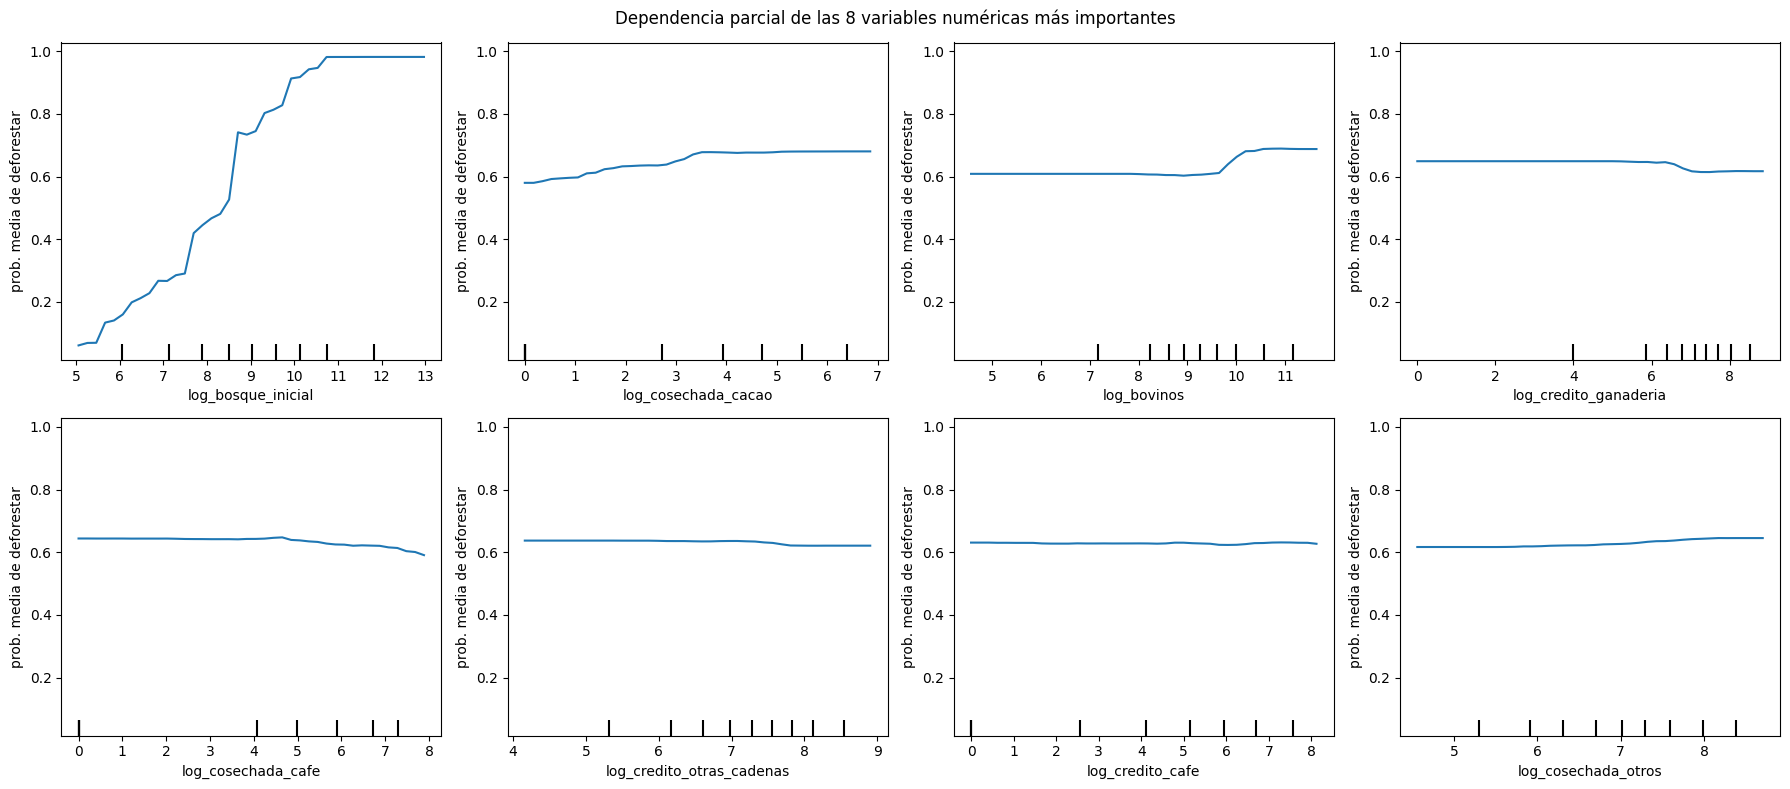

In [15]:
from sklearn.inspection import PartialDependenceDisplay

top_num = [c for c in importancia.index if c in NUMERICAS][:8]
fig, ax = plt.subplots(2, 4, figsize=(18, 8))
PartialDependenceDisplay.from_estimator(final, X_train, top_num, ax=ax.ravel(), grid_resolution=40,
                                        kind="average", response_method="predict_proba")
for a in ax.ravel():
    a.set_ylabel("prob. media de deforestar")
fig.suptitle("Dependencia parcial de las 8 variables numéricas más importantes")
plt.tight_layout(); plt.show()

In [16]:
# Dependencia parcial de las categoricas
filas = []
for var in CATEGORICAS:
    for cat in X_train[var].dropna().unique():
        filas.append({"variable": var, "categoria": cat, "prob_media": final.predict_proba(X_train.assign(**{var: cat}))[:, 1].mean()})
pd.DataFrame(filas).sort_values(["variable", "prob_media"], ascending=[True, False]).round(3)

,variable,categoria,prob_media
1,region,Caribe,0.657
0,region,Eje cafetero,0.628
5,region,Llano,0.626
4,region,Pacífico,0.625
3,region,Centro Sur,0.623
2,region,Centro Oriente,0.617
6,ruralidad,Rural,0.630
7,ruralidad,Rural disperso,0.628


## 12. Comparación de especificaciones

Se comparan con el AUC-ROC, con los hiperparámetros elegidos, entrenando con 2022–2024 (el modelo C necesita la deforestación del año
anterior, que no existe para 2021) y evaluando en 2025.

| Modelo | Variables |
|---|---|
| A. Estructural | `log_bosque_inicial`, región, ruralidad |
| B. Principal | A + crédito por cadena, cosecha por cultivo y bovinos (*t − 1*) |
| C. Con persistencia | B + deforestación del año anterior (`log_def_l1`) |

In [17]:
especificaciones = {"A. Estructural": ["log_bosque_inicial"], "B. Principal": NUMERICAS,
                    "C. Con persistencia": NUMERICAS + ["log_def_l1"]}
mejores = {k.replace("rf__", ""): v for k, v in busqueda.best_params_.items()}
train_c = train[train.anio >= 2022]
filas = []
for nombre, num in especificaciones.items():
    m = Pipeline([("pre", preprocesador(num)), ("rf", RandomForestClassifier(random_state=SEMILLA, n_jobs=-1, **mejores))])
    m.fit(train_c[num + CATEGORICAS], train_c.deforesta)
    filas.append({"modelo": nombre, **metricas(y_test, m.predict_proba(test[num + CATEGORICAS])[:, 1])})
comparacion = pd.DataFrame(filas).set_index("modelo")
comparacion.round(4)

,AUC-ROC
modelo,
A. Estructural,0.9064
B. Principal,0.9240
C. Con persistencia,0.9265


## 13. Guardado

En `datos/analisis/modelo_random_forest_rural/`, una carpeta ignorada por git.

In [18]:
import joblib

SALIDA = Path("datos/analisis/modelo_random_forest_rural")
SALIDA.mkdir(parents=True, exist_ok=True)
joblib.dump({"modelo": final, "umbral": UMBRAL, "variables": X_COLS, "hiperparametros": mejores,
             "regla_objetivo": REGLA_OBJETIVO, "bosque_min_ha": BOSQUE_MIN_HA}, SALIDA / "modelo_random_forest.joblib", compress=3)
test[["cod_dane", "nombre_departamento", "nombre_municipio", "anio", "def_ideam_ha", "deforesta"]].assign(
    prob_rf=prob_test, pred_rf=pred_test, prob_rf_totales=prob_ant, prob_persistencia=prob_pers).to_csv(SALIDA / "predicciones_prueba.csv", index=False)
importancia.to_csv(SALIDA / "importancia_variables.csv")
pd.concat({"bloque": imp_bloques, "actividad": imp_actividades}).to_csv(SALIDA / "importancia_bloques.csv")
tabla_cv.sort_values("AUC_val", ascending=False).to_csv(SALIDA / "grid_search_resultados.csv", index=False)
pd.concat({"evaluacion": tabla_eval, "especificaciones": comparacion}).to_csv(SALIDA / "metricas.csv")
print(sorted(f.name for f in SALIDA.iterdir()))

['grid_search_resultados.csv', 'importancia_bloques.csv', 'importancia_variables.csv', 'metricas.csv', 'modelo_random_forest.joblib', 'predicciones_prueba.csv']


## 14. Conclusiones

### 14.1 Configuración

- **Muestra:** la misma del gradient boosting. Son 639 municipios rurales y rurales dispersos con bosque, 3.195
  filas en total, 63,2 % con deforestación. La coincidencia con sus filas se verificó en el paso 4.
- **Partición:** entrenamiento 2021–2024 (2.556 filas: 947 ceros y 1.609 unos) y prueba 2025 (639 municipios:
  229 ceros y 410 unos).
- **Variables:** las 15 por actividad productiva, del año anterior.

**Hiperparámetros** (192 combinaciones × 5 pliegues agrupados por municipio, 5,5 min). Ganaron 300 árboles,
`max_depth = 12`, `min_samples_leaf = 25`, `max_features = 0,5` y sin pesos por clase: la misma configuración de
la versión con todos los municipios, salvo el número de árboles. El AUC de validación es 0,911 y el
*out-of-bag* 0,922.

### 14.2 Comparación de modelos en 2025 (639 municipios rurales)

| Modelo | AUC-ROC | Falsos positivos | Falsos negativos | Aciertos |
|---|---|---|---|---|
| **Gradient boosting (equipo)** | **0,928** | 50 | **50** | 539 (84,4 %) |
| **RF por actividad (15 variables)** | 0,925 | **44** | 55 | **540 (84,5 %)** |
| RF de totales (9 variables) | 0,920 | 55 | 47 | 537 (84,0 %) |
| Persistencia (año anterior) | 0,827 | 50 | 52 | 537 (84,0 %) |

- **Con la misma muestra, el Random Forest y el gradient boosting quedan prácticamente empatados.** El gradient
  boosting tiene un AUC 0,003 mayor y el Random Forest acierta un municipio más (540 frente a 539).
- **Se equivocan de forma distinta.** El Random Forest comete menos falsos positivos (44 frente a 50): marca menos
  municipios que en realidad no deforestaron. El gradient boosting deja escapar menos municipios que sí
  deforestaron (50 frente a 55).
- **Con la muestra rural, el Random Forest mejora** frente a la versión con todos los municipios con bosque (AUC
  0,925 frente a 0,919).
- **Frente a la persistencia, la ventaja vuelve a estar en el AUC, no en los aciertos.** Repetir el estado del año
  anterior ya acierta 537 municipios (84 %), porque en los municipios rurales la deforestación es todavía más
  persistente.
- **Desagregar por actividad ayuda poco:** el RF por actividad tiene un AUC 0,004 mayor que el de totales y acierta
  3 municipios más.

**Especificaciones (AUC-ROC en 2025, entrenando con 2022–2024):** estructural (bosque, región y ruralidad) 0,906 →
principal (15 variables) 0,922 → con la deforestación del año anterior 0,928.

### 14.3 Importancia de las variables

**Por bloque** (caída del AUC al permutar el bloque en 2025): bosque 0,304 · cosecha por cultivo 0,027 ·
región 0,011 · bovinos 0,010 · crédito por cadena 0,008 · ruralidad 0,000.

**Por actividad** (crédito y área juntos): **cacao 0,028** · ganadería 0,012 · café 0,006 · otras 0,003 ·
arroz 0,001 · palma 0,000.

| Rango | Variable | Caída del AUC | Efecto sobre la probabilidad de deforestar (media 0,63) |
|---|---|---|---|
| 1 | Bosque inicial | **0,308** | **Fuerte, positivo:** 0,24 con 432 ha → 0,74 con 8.400 ha → **0,94** con 136.000 ha |
| 2 | Área de cacao | 0,019 | **Positivo:** 0,58 sin cacao → 0,65 con 10 ha → **0,70** con 830 ha |
| 3 | Región | 0,011 | Caribe 0,66; Llano 0,64; Eje cafetero 0,64; Centro Sur 0,63; Pacífico 0,63; Centro Oriente 0,61 |
| 4 | Bovinos | 0,009 | **Positivo en hatos grandes:** 0,61 hasta 10.500 cabezas → **0,67** con 70.000 |
| 5 | Crédito a la ganadería | 0,003 | Casi plano: entre 0,62 y 0,64 |
| 6 | Crédito al cacao | 0,002 | Positivo leve: 0,62 → 0,66 |
| 7 | Crédito al café | 0,002 | Negativo leve: 0,64 → 0,62 |
| 8–15 | Resto (otros cultivos, otras cadenas, área de café, arroz, palma, ruralidad) | ≤ 0,002 | Casi nulos |

En la muestra rural se mantienen las conclusiones de la versión anterior: **el bosque domina**, el **cacao** es
la actividad más asociada a la deforestación, le sigue la **ganadería** (hatos grandes), y el **café** se asocia
levemente con menos deforestación. El crédito, por sí solo, aporta poco. La ruralidad deja de aportar, porque
ahora solo distingue entre "Rural" y "Rural disperso".